# Nonlinear Registration

### Report prepared by Group G2

**André Ribau · Mara Dimitriu · Safiya Aden · Sarah Heurtevent**

# 1. Introduction

In this exercise, we investigate nonlinear image registration using two 2D sagittal brain MRI images from different subjects. We implement a registration method based on the sum of squared differences (SSD) and the Gauss–Newton algorithm to estimate a deformation that improves the alignment between the images.

# 2. Data Preparation

### 2.1 Import Libraries

In [6]:
import numpy as np
np.set_printoptions( suppress=True )
from matplotlib import pyplot as plt
plt.ion()
from scipy.ndimage import map_coordinates
import nibabel as nib

### 2.2 Load MRI Data and Extract 2D Slices

In [7]:
fixed = nib.load( 'IXI092-HH-1436-T1.nii.gz' ).get_fdata()
moving = nib.load( 'IXI097-HH-1619-T1_resampled.nii.gz' ).get_fdata()

fixed, moving = fixed[ ..., 73 ], moving[ ..., 73 ] # get slices

### 2.3 Image and Grid Visualization

The following functions are used to consistently visualize the MRI images and coordinate grids throughout the exercise. The fixed and moving images, together with the initial image grid, are displayed below.

Text(0.5, 0.98, 'Image Grid')

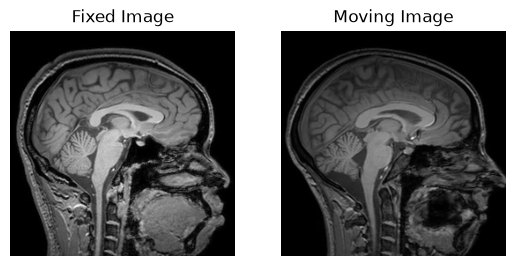

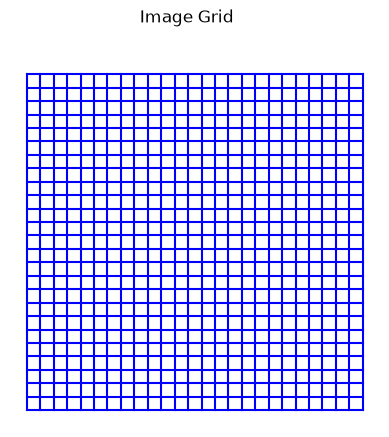

In [8]:
def visualize_image( ax, im, **kwargs ):
    # Visualize an image the same way the grid and vector fields are drawn: to the right means
    # x1 (row number in image matrix) goes up, and to the top means x2 (column number in image 
    # matrix) goes up.
    ax.imshow( np.flipud( im.T ), **kwargs )
    ax.set_aspect( 'equal' )
    ax.axis( False )

def plot_grid( ax, X1, X2, **kwargs ):
    for i in range(X1.shape[0]):
        ax.plot(X1[i,:], X2[i,:], **kwargs)
    for i in range(X1.shape[1]):
        ax.plot(X1[:,i], X2[:,i], **kwargs)

def visualize_grid( ax, X1, X2 ):
    N1, N2 = X1.shape
    plot_grid( ax, X1[ ::10, ::10 ], X2[ ::10, ::10 ], color='b' )
    ax.set_aspect( 'equal' )
    ax.axis( False )

fixed = np.flipud( fixed )
moving = np.flipud( moving )

fig, ax = plt.subplots( 1, 2 )
visualize_image( ax[0], fixed, cmap='gray' )
visualize_image( ax[1], moving, cmap='gray' )
ax[0].set_title("Fixed Image")
ax[1].set_title("Moving Image")

X1, X2 = np.meshgrid( np.arange(fixed.shape[0]), np.arange(fixed.shape[1]), indexing='ij' )
fig, ax = plt.subplots()
visualize_grid( ax, X1, X2 )
fig.suptitle("Image Grid")

### 2.4 Histogram Plotting

Image histograms are used to examine the distribution of intensity values. The code below demonstrates how an image histogram is computed and how a specific intensity value can be indicated on the histogram.

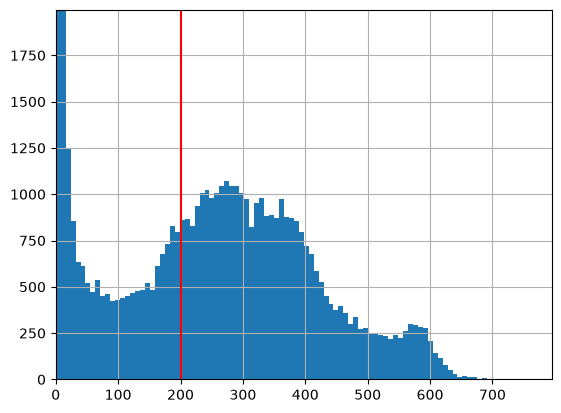

In [9]:
data = fixed
value = np.median( data )

histogram, edges = np.histogram( data.ravel(), bins=100 )
binCenters = ( edges[ 1: ] + edges[ :-1 ] ) / 2
binWidth = edges[ 1 ] - edges[ 0 ]
fig, ax = plt.subplots()
ax.bar( binCenters, histogram, width=binWidth )
ax.set_ylim( 0, histogram[1:].max() )  # clip the entry for background
ax.set_xlim( 0, data.max() )
ax.plot( [ value ]*2, ax.get_ylim(), 'r' )
ax.grid()


# 3. Tasks

## Task 1: Normalize the intensity values of both images

### Task 1.1  Normalization using maximum intensity

First, the fixed and moving images are normalized by their respective maximum intensity values. This scales the intensity values of both images to the range [0,1], where 0 corresponds to the minimum intensity and 1 to the maximum intensity.

In [10]:
# Normalize each image by its maximum intensity
fixed_max = fixed / np.max(fixed)
moving_max = moving / np.max(moving)

print("Fixed range:", fixed_max.min(), fixed_max.max())
print("Moving range:", moving_max.min(), moving_max.max())

Fixed range: 0.0 1.0
Moving range: 0.0 1.0


The normalized fixed and moving images are displayed side by side below for visual comparison:

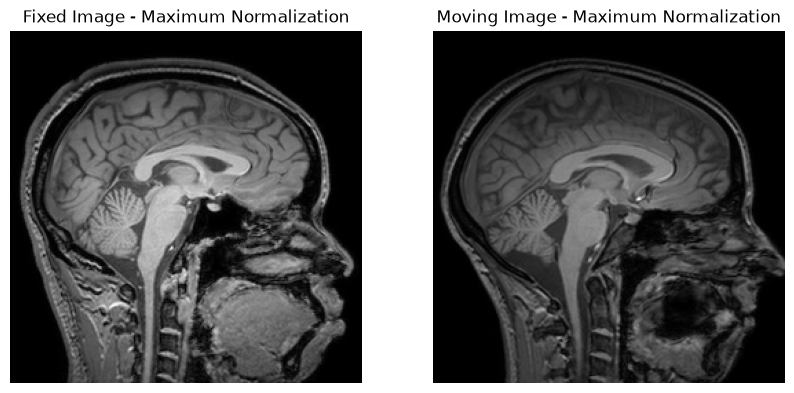

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

visualize_image(ax[0], fixed_max, cmap='gray', vmin=0, vmax=1)
visualize_image(ax[1], moving_max, cmap='gray', vmin=0, vmax=1)

ax[0].set_title("Fixed Image - Maximum Normalization")
ax[1].set_title("Moving Image - Maximum Normalization")

plt.show()

To further compare the normalized intensity distributions, histograms are computed for both the fixed and moving images.

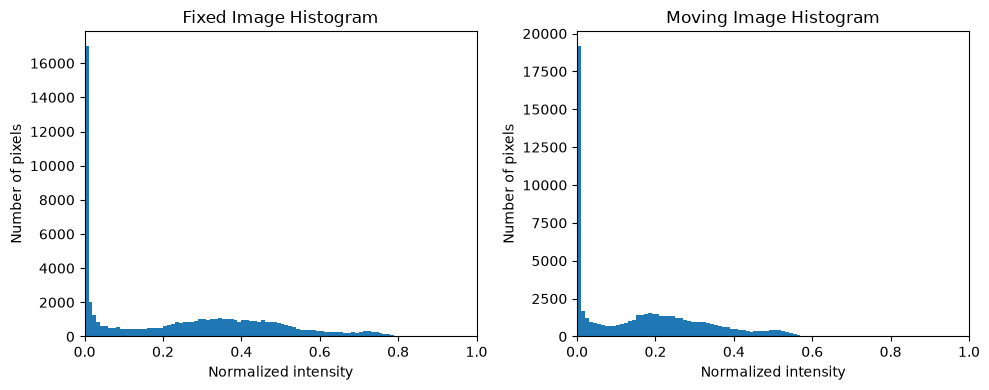

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].hist(fixed_max.ravel(), bins=100)
ax[0].set_xlim(0, 1)
ax[0].set_title("Fixed Image Histogram")
ax[0].set_xlabel("Normalized intensity")
ax[0].set_ylabel("Number of pixels")

ax[1].hist(moving_max.ravel(), bins=100)
ax[1].set_xlim(0, 1)
ax[1].set_title("Moving Image Histogram")
ax[1].set_xlabel("Normalized intensity")
ax[1].set_ylabel("Number of pixels")

plt.tight_layout()
plt.show()

Both images were normalized by dividing their intensity values by their respective maximum intensity. Although this scales both images to the range [0,1], the histograms show that their intensity distributions are still different. In particular, the fixed image has generally higher normalized intensities than the moving image. Therefore, normalization by the maximum intensity does not make the two images fully comparable.

### Task 1.2 Robust maximum intensity

A few very bright pixels can make the maximum intensity unusually high. To avoid this, we use a robust maximum, defined as the 99th percentile. This means that 99% of the pixels have intensity values below this value.

In [13]:
# Calculate the 99th percentile for each image
fixed_robust_max = np.percentile(fixed, 99)
moving_robust_max = np.percentile(moving, 99)

print("Fixed robust maximum:", fixed_robust_max)
print("Moving robust maximum:", moving_robust_max)

Fixed robust maximum: 599.0
Moving robust maximum: 672.0342437744141


The robust maximum intensity is 599.0 for the fixed image and 672.03 for the moving image. These values represent the 99th percentile of each image. Now we can showcase these values on the histograms.

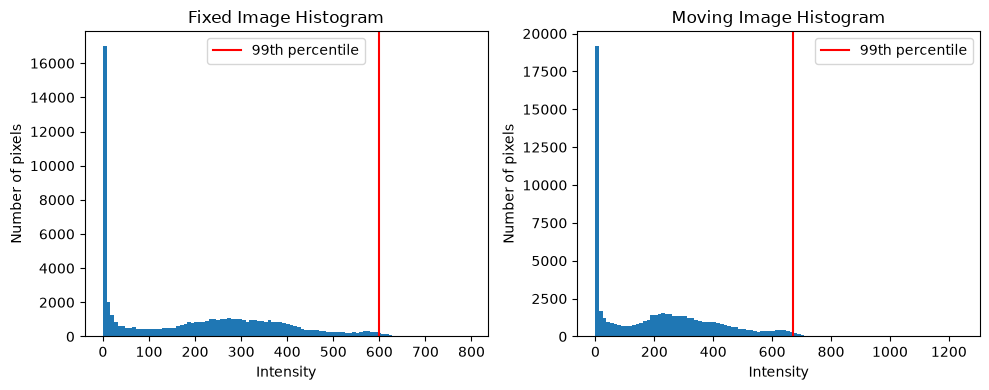

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Fixed image
ax[0].hist(fixed.ravel(), bins=100)
ax[0].axvline(fixed_robust_max, color='r', label='99th percentile')
ax[0].set_title("Fixed Image Histogram")
ax[0].set_xlabel("Intensity")
ax[0].set_ylabel("Number of pixels")
ax[0].legend()

# Moving image
ax[1].hist(moving.ravel(), bins=100)
ax[1].axvline(moving_robust_max, color='r', label='99th percentile')
ax[1].set_title("Moving Image Histogram")
ax[1].set_xlabel("Intensity")
ax[1].set_ylabel("Number of pixels")
ax[1].legend()

plt.tight_layout()
plt.show()

The red lines show the robust maximum (99th percentile) for each image. As shown in the histograms above, most pixel intensities are below the robust maximum, while only a few pixels have higher values. By using the robust maximum, these few high intensity values have less effect on the normalization.

### Task 1.3 Normalization using the robust maximum

Now, the images are normalized again using their robust maximum values. Any intensity values above the robust maximum are clipped so that all normalized values stay between 0 and 1.

In [15]:
# Normalize using the robust maximum
fixed_robust = fixed / fixed_robust_max
moving_robust = moving / moving_robust_max

# Clip values to the range [0,1]
fixed_robust = np.clip(fixed_robust, 0, 1)
moving_robust = np.clip(moving_robust, 0, 1)

print("Fixed range:", fixed_robust.min(), fixed_robust.max())
print("Moving range:", moving_robust.min(), moving_robust.max())

Fixed range: 0.0 1.0
Moving range: 0.0 1.0


Now that we have made sure the images are normalized using the robust maximum, we can display the images and their histograms again to see the results.

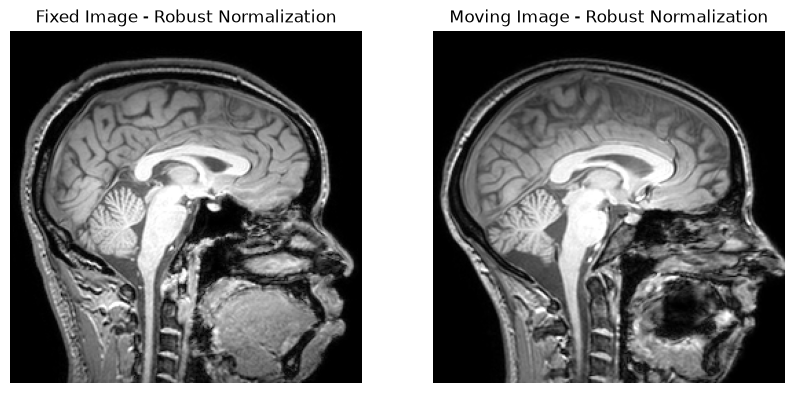

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

visualize_image(ax[0], fixed_robust, cmap='gray', vmin=0, vmax=1)
visualize_image(ax[1], moving_robust, cmap='gray', vmin=0, vmax=1)

ax[0].set_title("Fixed Image - Robust Normalization")
ax[1].set_title("Moving Image - Robust Normalization")

plt.show()


Compared with maximum normalization, the robust-normalized images have better contrast and the brain structures are easier to see. The difference is especially clear in the moving image, which appears much darker with maximum normalization.

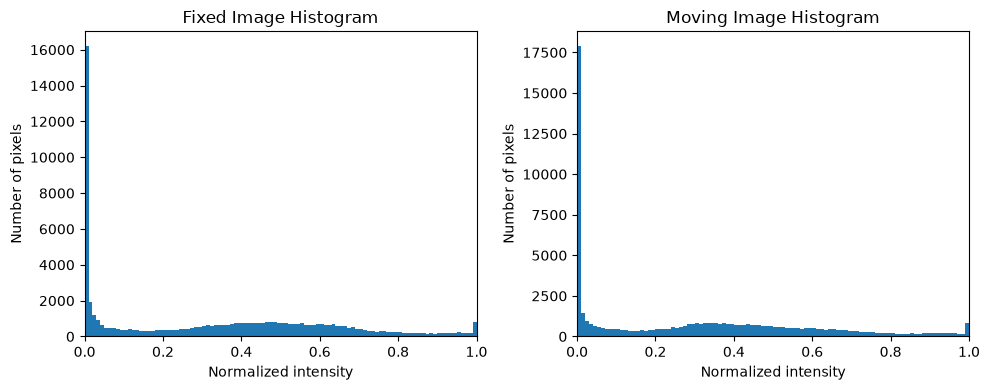

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].hist(fixed_robust.ravel(), bins=100)
ax[0].set_xlim(0, 1)
ax[0].set_title("Fixed Image Histogram")
ax[0].set_xlabel("Normalized intensity")
ax[0].set_ylabel("Number of pixels")

ax[1].hist(moving_robust.ravel(), bins=100)
ax[1].set_xlim(0, 1)
ax[1].set_title("Moving Image Histogram")
ax[1].set_xlabel("Normalized intensity")
ax[1].set_ylabel("Number of pixels")

plt.tight_layout()
plt.show()

The histograms are now more similar in shape and spread. The main intensity values of both images are distributed over a similar range, although the fixed image still has slightly higher intensities overall.

### Task 1.4 Choice of Normalization Method

The robust maximum normalization makes the intensities of the two images more comparable. After normalization, the histograms have a more similar distribution and the images have more similar brightness and contrast. Therefore, the robust maximum normalization will be used for the rest of the exercise.

In [18]:
fixed = fixed_robust
moving = moving_robust

## Task 2: Create basis functions for nonlinear deformation

To model the nonlinear deformation, we use cubic B-spline basis functions. First, 7 basis functions are created in each image direction and then combined to create 7 × 7 = 49 two-dimensional basis functions covering the whole fixed image. The cubic B-spline function from Exercise 1 is reused to create the basis functions.

In [19]:
def eval_BSpline(x, order=0):
    """
    Evaluates the uniform B-spline of order "order" at the locations in vector "x".
    Supports orders 0, 1, and 3.
    """
    
    x = np.asarray(x, dtype=float)
    abs_x = np.abs(x)
    y = np.zeros_like(x)

    if order == 0:
        inside_mask = abs_x < 0.5
        edge_mask = abs_x == 0.5
        y[inside_mask] = 1.0
        y[edge_mask] = 0.5

    elif order == 1:
        mask = abs_x < 1.0
        y[mask] = 1.0 - abs_x[mask]

    elif order == 3:
        inner_mask = abs_x < 1.0
        outer_mask = (abs_x >= 1.0) & (abs_x < 2.0)

        x_inner = abs_x[inner_mask]
        squared_term = x_inner ** 2
        cubed_term = x_inner ** 3
        y[inner_mask] = 2/3 - squared_term + 0.5 * cubed_term

        x_outer = abs_x[outer_mask]
        base = 2 - x_outer
        y[outer_mask] = (base ** 3) / 6

    return y

### Task 2.1 Creating the B-spline Basis Functions

We create 7 cubic B-spline basis functions in each image direction. The basis functions are distributed across the size of the fixed image. Cubic B-splines are suitable for this deformation model because each basis function has local support, allowing the deformation to be controlled locally while varying smoothly across the image.

In [20]:
# Image dimensions
N1, N2 = fixed.shape

# Number of basis functions in each direction
M1 = 7
M2 = 7

# Image coordinates
x1 = np.arange(N1)
x2 = np.arange(N2)

# Distance between the basis function centers
h1 = (N1 - 1) / (M1 - 1)
h2 = (N2 - 1) / (M2 - 1)

# Create the 1D basis functions
Phi1 = np.zeros((N1, M1))
Phi2 = np.zeros((N2, M2))

for m in range(M1):
    Phi1[:, m] = eval_BSpline((x1 - m*h1) / h1, order=3)

for m in range(M2):
    Phi2[:, m] = eval_BSpline((x2 - m*h2) / h2, order=3)

print("Phi1 shape:", Phi1.shape)
print("Phi2 shape:", Phi2.shape)

Phi1 shape: (256, 7)
Phi2 shape: (256, 7)


Seven B-spline basis functions were created in each image direction. Since the image size is 256 × 256, both $\Phi_1$  and $\Phi_2$  have a shape of 256 × 7.

### Task 2.2 Creating the 2D Basis Functions

The 1D basis functions from the two image directions are combined using the Kronecker product to create the 2D basis functions:

$$
\Phi = \Phi_2 \otimes \Phi_1
$$

where $\Phi_1$ and $\Phi_2$ contain the seven basis functions in each image direction. Therefore, the total number of 2D basis functions is:

$$
M = M_1M_2 = 7 \times 7 = 49.
$$

In [21]:
Phi_49 = np.kron(Phi2, Phi1)

print("Shape:", Phi_49.shape)
print("Number of basis functions:", Phi_49.shape[1])

Shape: (65536, 49)
Number of basis functions: 49


Since the image contains 256 x 256 = 65,536 pixels, each column of $\Phi$ represents one 2D basis function evaluated at all image pixels. Therefore, the resulting basis matrix has shape 65,536 x 49.

### Task 2.3 Visualization of the Basis Functions

The 49 basis functions are shown below in a 7 × 7 grid. Each basis function covers a different local area of the image.

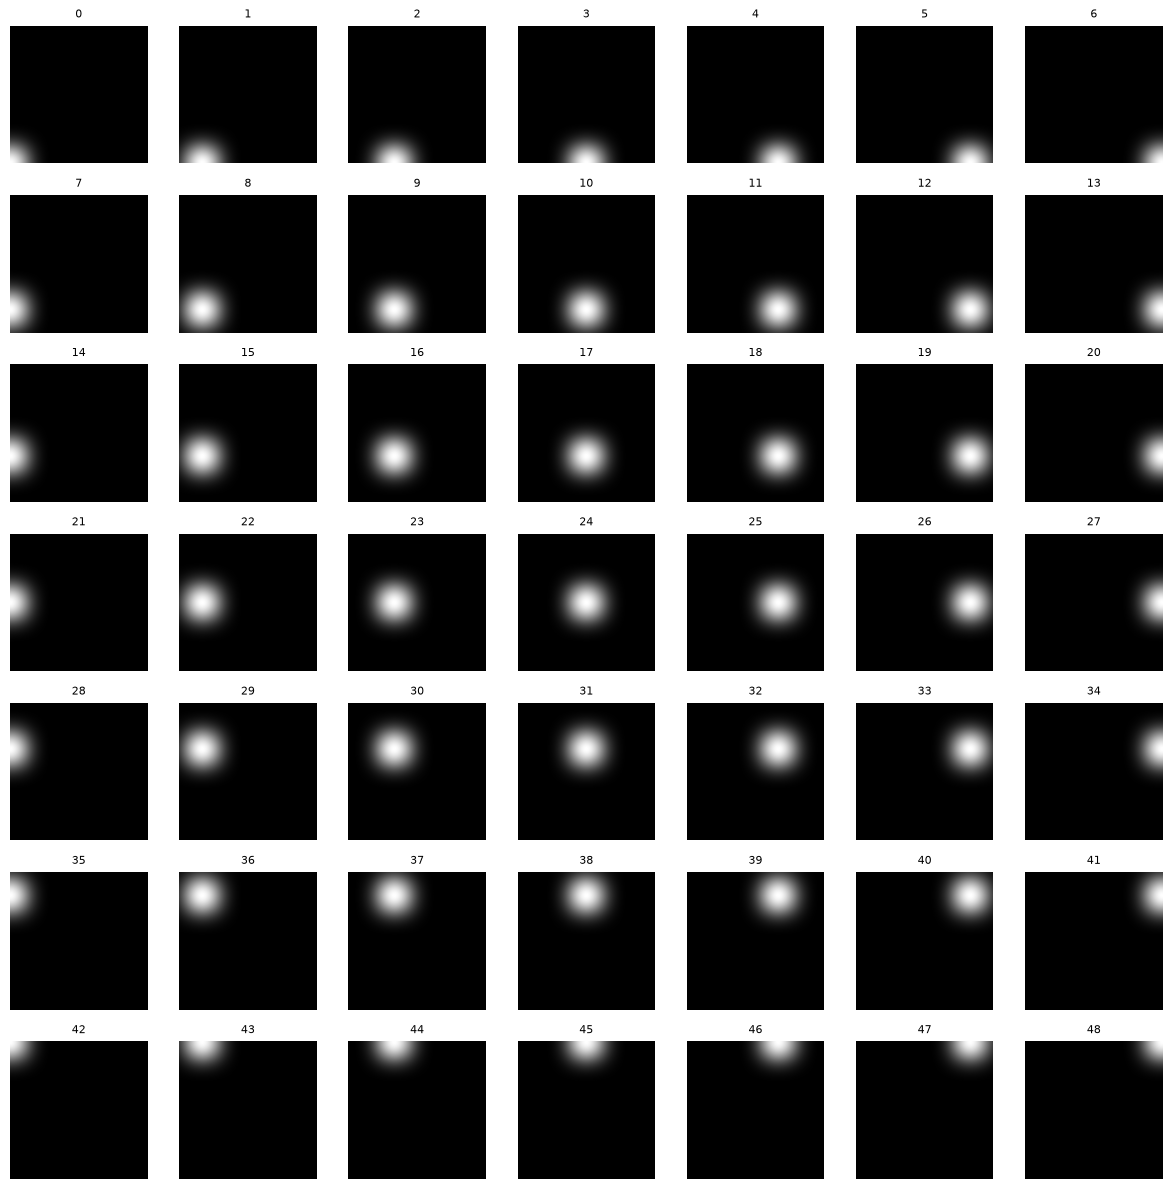

In [22]:
fig, axes = plt.subplots(7, 7, figsize=(12, 12))

for i in range(49):
    basis_function = Phi_49[:, i].reshape(N1, N2, order='F')

    ax = axes[i // 7, i % 7]
    visualize_image(ax, basis_function, cmap='gray')
    ax.set_title(f"{i}", fontsize=8)

plt.tight_layout()
plt.show()

As shown in the figure above, each basis function affects a different part of the image, with the strongest effect shown by the bright area. Together, the 49 functions cover the whole image.

### Task 2.4 Selecting the Central Basis Functions

 For the deformation model, only the central (5 x 5) basis functions are retained. Removing the outer basis functions constrains the deformation near the image boundaries and reduces boundary effect

In [23]:
# Keep only the 5 central basis functions in each direction
Phi1_central = Phi1[:, 1:-1]
Phi2_central = Phi2[:, 1:-1]

# Create the final 2D basis matrix
Phi = np.kron(Phi2_central, Phi1_central)

print("Final Phi shape:", Phi.shape)
print("Number of retained basis functions:", Phi.shape[1])

Final Phi shape: (65536, 25)
Number of retained basis functions: 25


After removing the basis functions at the image edges, 25 basis functions remain. These will be helpful to model the nonlinear deformation in the next tasks.

## Task 3: Manipulate the image locally with basis functions

### Background & Context
In this task, we manipulate the spatial transformation model:
$$y_d(\mathbf{x}, \mathbf{w}_d) = x_d + \delta_d(\mathbf{x}, \mathbf{w}_d), \quad d \in \{1, 2\}$$

where the residual deformation field $\boldsymbol{\delta}(\mathbf{x})$ is parameterized as a linear combination of localized 2D basis functions $\phi_m(\mathbf{x})$:
$$\delta_d(\mathbf{x}, \mathbf{w}_d) = \sum_{m=0}^{M-1} w_{d,m} \phi_m(\mathbf{x}) = \boldsymbol{\Phi} \mathbf{w}_d$$

Here, we reuse the design matrix $\boldsymbol{\Phi} \in \mathbb{R}^{N \times 25}$ created in Task 2, which contains $M = 25$ basis functions arranged on a regular $5 \times 5$ spatial grid.
- $\mathbf{w}_1$ governs displacements along dimension 1 ($x_1$, horizontal axis in the figures).
- $\mathbf{w}_2$ governs displacements along dimension 2 ($x_2$, vertical axis in the figures).

To assess the impact of local parameter weights, we:
1. Deform the regular pixel coordinate grid $\mathbf{x}$ to $\mathbf{y}(\mathbf{x}, \mathbf{w})$ and display it using `visualize_grid()`.
2. Resample the moving image $\mathcal{M}$ at the mapped coordinates $\mathbf{y}$ using `scipy.ndimage.map_coordinates` and display it with `visualize_image()`.

### Task 3.1 Helper function

The following function computes the deformed coordinates $(Y_1, Y_2)$ from the weight vectors $\mathbf{w}_1$ and $\mathbf{w}_2$, and resamples the moving image at those mapped coordinates. Since the rows of $\boldsymbol{\Phi} = \boldsymbol{\Phi}_2 \otimes \boldsymbol{\Phi}_1$ are ordered with $x_1$ varying fastest, the displacement vectors $\boldsymbol{\Phi}\mathbf{w}_d$ are reshaped into images in column-major (Fortran) order.

In [24]:
def warp_and_resample(w1, w2, moving_img, Phi, X1, X2):
    # Displacement field: delta_d = Phi @ w_d
    # (Phi rows are ordered with x1 varying fastest -> reshape in Fortran order)
    delta1 = (Phi @ w1).reshape(X1.shape, order='F')
    delta2 = (Phi @ w2).reshape(X2.shape, order='F')
    
    # Deformed coordinates: y(x, w) = x + delta
    Y1 = X1 + delta1
    Y2 = X2 + delta2
    
    # Resample moving image: M(y(x, w)) using map_coordinates
    coords = np.array([Y1.ravel(), Y2.ravel()])
    warped_moving = map_coordinates(moving_img, coords, order=1, mode='nearest').reshape(moving_img.shape)
    
    return Y1, Y2, warped_moving

### Task 3.2: Experiment 1 — Local Deformation Along Dimension 1 Only ($\mathbf{w}_1 \neq \mathbf{0}, \mathbf{w}_2 = \mathbf{0}$)

In this experiment, all entries of $\mathbf{w}_2$ are set to zero, and all entries of $\mathbf{w}_1$ are set to zero except for one basis function. 
We pick index $m = 12$, which corresponds to the center of the $5 \times 5$ grid (row 2, column 2 in grid indexing), located near the center of the image, around the top of the brainstem.

We test three different values for $w_{1, 12}$:
- $w_{1, 12} = -15.0$ (moderate negative displacement)
- $w_{1, 12} = +15.0$ (moderate positive displacement)
- $w_{1, 12} = +30.0$ (large positive displacement)

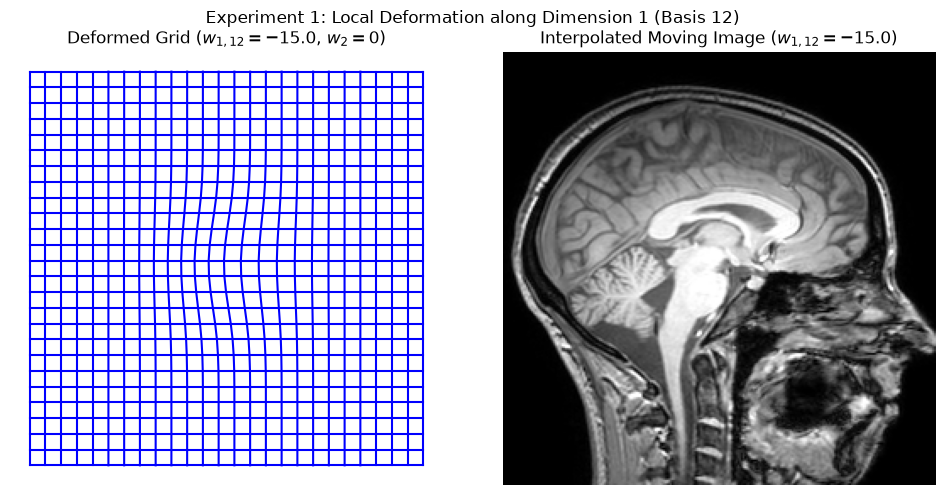

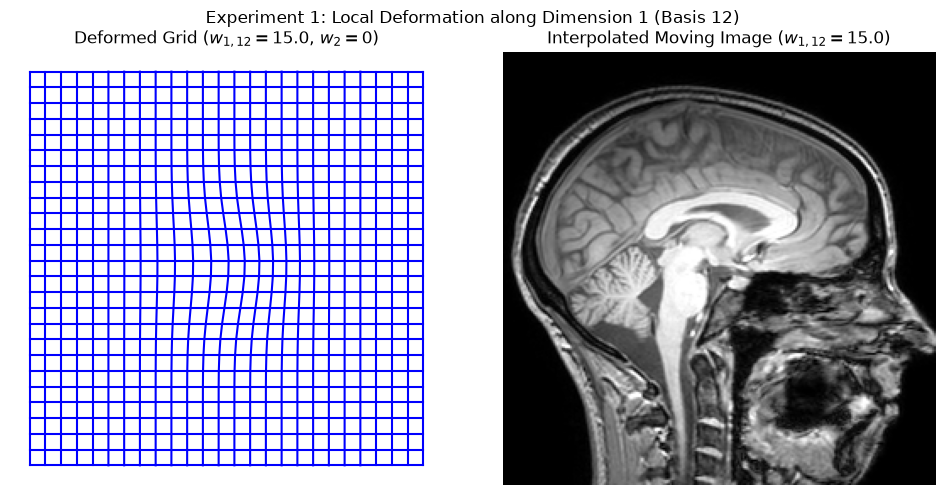

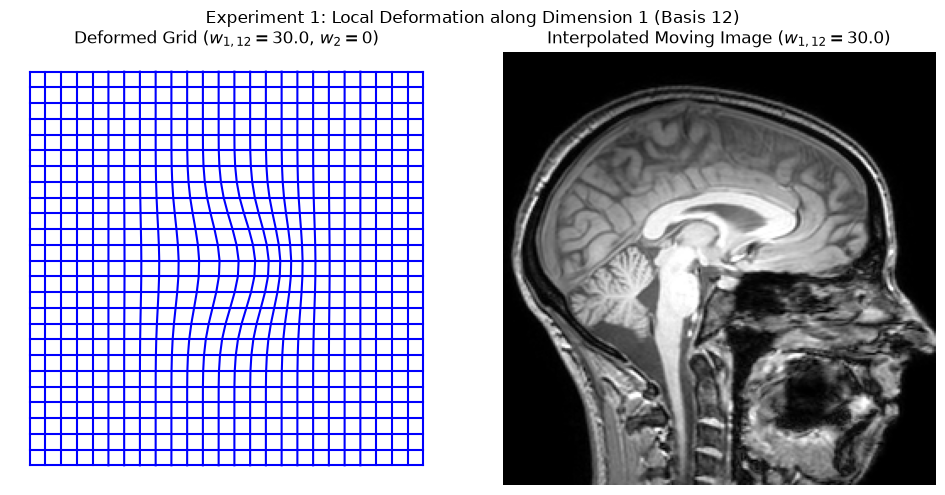

In [25]:
# Select the center basis function in the 5x5 grid (index 12)
m_center = 12

# Test values for the non-zero element in w1
w1_test_values = [-15.0, 15.0, 30.0]

for val in w1_test_values:
    # Initialize both weight vectors of size 25 to zero
    w1 = np.zeros(25)
    w2 = np.zeros(25)
    
    # Set the single non-zero entry in w1
    w1[m_center] = val
    
    # Compute deformed grid coordinates and interpolated moving image
    Y1, Y2, warped_img = warp_and_resample(w1, w2, moving, Phi, X1, X2)
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    
    # (1) Deformed image grid
    visualize_grid(axes[0], Y1, Y2)
    axes[0].set_title(f"Deformed Grid ($w_{{1,{m_center}}} = {val}$, $w_2 = 0$)")
    
    # (2) Interpolated moving image
    visualize_image(axes[1], warped_img, cmap='gray', vmin=0, vmax=1)
    axes[1].set_title(f"Interpolated Moving Image ($w_{{1,{m_center}}} = {val}$)")
    
    plt.suptitle(f"Experiment 1: Local Deformation along Dimension 1 (Basis {m_center})", fontsize=12)
    plt.tight_layout()
    plt.show()

#### Observations on Experiment 1
- **Direction.** Since $\mathbf{w}_2 = \mathbf{0}$, the displacement acts only along $x_1$, which is the horizontal direction in the figures. Horizontal grid lines therefore stay straight, while vertical grid lines bend.
- **Sign.** For $w_{1,12} = +15$, the grid points around the center move to the right, so each pixel of the fixed image samples the moving image further to the right. As a result, the anatomy around the center appears shifted to the left in the resampled image. A negative weight produces the opposite effect.
- **Interpretation of the grid.** The deformed grid shows where each fixed-image pixel samples the moving image, not how the image itself moves. Where grid lines are crowded together, a small region of the moving image fills many output pixels and appears magnified. Where they are spread apart, the region appears compressed.
- **Magnitude.** The displacement scales linearly with the weight: its maximum equals the weight times the peak value of the basis function (≈ 0.44), i.e. about 6.7 pixels for $|w_{1,12}| = 15$ and 13.3 pixels for $w_{1,12} = 30$. All three deformations remain smooth and invertible. Folding of the grid would only occur for much larger weights ($|w| \gtrsim 96$), where the transformation would no longer be one-to-one.
- **Locality.** The displacement is largest at the center of basis function 12 and decreases smoothly to zero outside its support, so the image borders remain unaffected.

### Task 3.3: Experiment 2 — Combined 2D Local Deformation ($\mathbf{w}_1 \neq \mathbf{0}, \mathbf{w}_2 \neq \mathbf{0}$)

In this experiment, we apply a non-zero value to both $w_{1, 12}$ and $w_{2, 12}$ simultaneously, controlling the same 2D basis function in both spatial dimensions.

We evaluate three weight pairs:
- $(w_{1,12}, w_{2,12}) = (+15.0, +15.0)$: equal positive weights (diagonal displacement)
- $(w_{1,12}, w_{2,12}) = (+15.0, -15.0)$: opposite weights (displacement along the other diagonal)
- $(w_{1,12}, w_{2,12}) = (-10.0, +20.0)$: asymmetric displacement

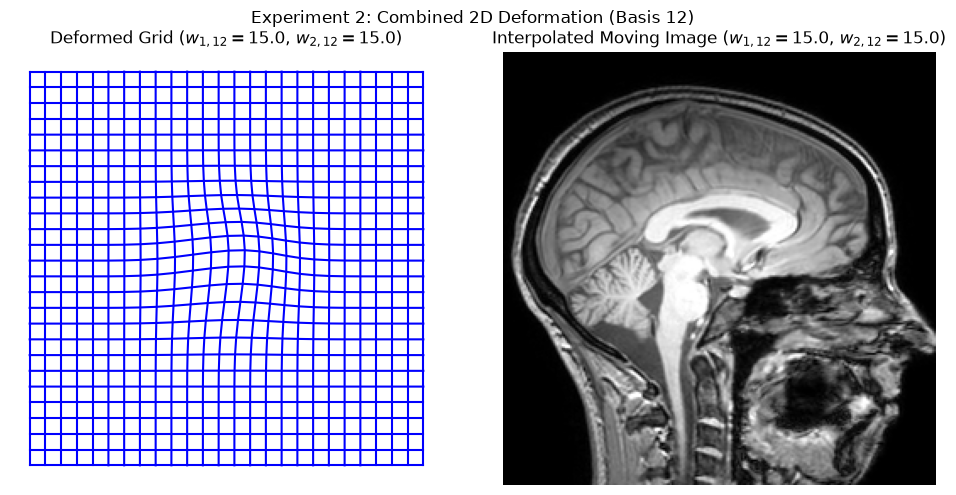

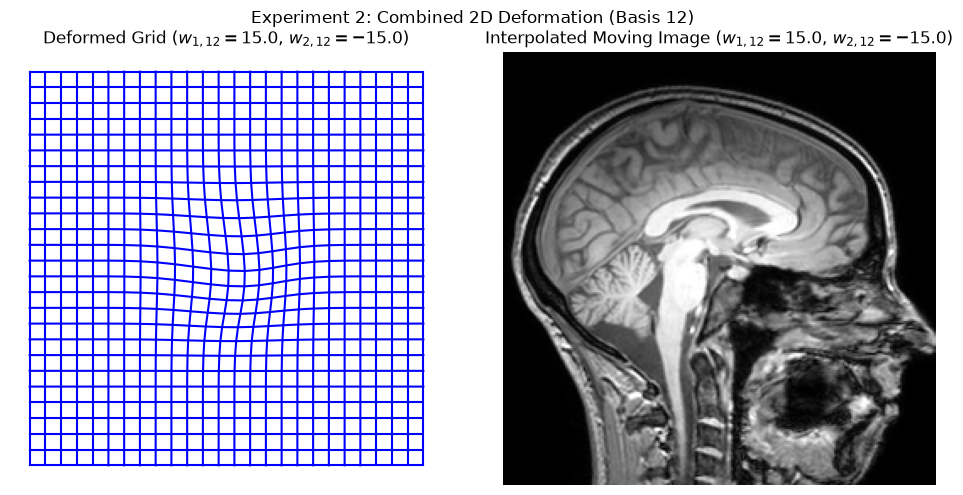

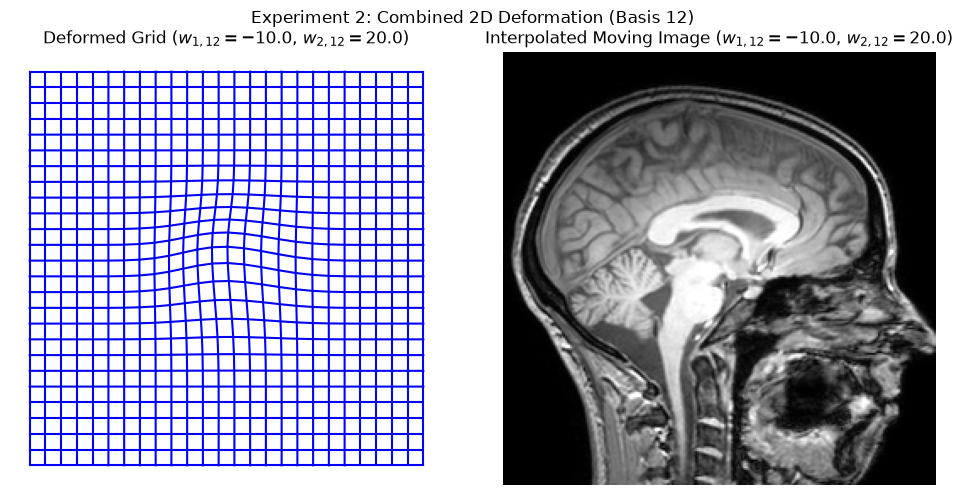

In [26]:
# Experiment 2: Apply non-zero values to both w1 and w2 for basis function 12
weight_pairs = [
    (15.0, 15.0),
    (15.0, -15.0),
    (-10.0, 20.0)
]

for val1, val2 in weight_pairs:
    w1 = np.zeros(25)
    w2 = np.zeros(25)
    
    w1[m_center] = val1
    w2[m_center] = val2
    
    # Compute deformed grid coordinates and interpolated moving image
    Y1, Y2, warped_img = warp_and_resample(w1, w2, moving, Phi, X1, X2)
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    
    # (1) Deformed image grid
    visualize_grid(axes[0], Y1, Y2)
    axes[0].set_title(f"Deformed Grid ($w_{{1,{m_center}}}={val1}$, $w_{{2,{m_center}}}={val2}$)")
    
    # (2) Interpolated moving image
    visualize_image(axes[1], warped_img, cmap='gray', vmin=0, vmax=1)
    axes[1].set_title(f"Interpolated Moving Image ($w_{{1,{m_center}}}={val1}$, $w_{{2,{m_center}}}={val2}$)")
    
    plt.suptitle(f"Experiment 2: Combined 2D Deformation (Basis {m_center})", fontsize=12)
    plt.tight_layout()
    plt.show()

#### Observations on Experiment 2
- **Direction.** Both displacement components share the same spatial profile $\phi_{12}$, so at every pixel the displacement points in the direction $(w_{1,12}, w_{2,12})$, with a magnitude proportional to $\phi_{12}$. The maximum displacement is $0.44\sqrt{w_{1,12}^2 + w_{2,12}^2}$, i.e. about 9.4 pixels for $(15, 15)$ and 9.9 pixels for $(-10, 20)$.
- **Examples.** For $(15, 15)$, the grid around the center is pushed diagonally up and to the right, and the anatomy in the resampled image moves down and to the left. For $(15, -15)$, the grid is pushed down and to the right. For $(-10, 20)$, it is pushed mainly upward and slightly to the left.
- **Local versus global.** Unlike an affine transformation, which acts on the entire image, this deformation is confined to the support of a single basis function. Combining all 25 basis functions with different weights therefore allows smooth, spatially varying deformations, which the registration in Task 4 will estimate.

## Task 4: Implement Gauss-Newton optimization

### Background & Context
The registration searches for the weights $\mathbf{w} = (\mathbf{w}_1^T, \mathbf{w}_2^T)^T$ that minimize the sum of squared differences (SSD) between the fixed image and the deformed moving image:
$$
E(\mathbf{w}) = \sum_{n=1}^N \tau_n^2, \qquad \tau_n = \mathcal{F}(\mathbf{x}_n) - \mathcal{M}(\mathbf{y}(\mathbf{x}_n, \mathbf{w})) .
$$
The SSD assumes that corresponding tissues have similar intensities, which is why the intensity normalization of Task 1 is needed.

Since $\mathcal{M}(\mathbf{y}(\mathbf{x}_n, \mathbf{w}))$ depends nonlinearly on $\mathbf{w}$, there is no closed-form solution. The **Gauss-Newton** algorithm instead linearizes the deformed moving image around the current weights. By the chain rule,
$$
\frac{\partial \mathcal{M}(\mathbf{y}(\mathbf{x}_n, \mathbf{w}))}{\partial w_{d,m}} = g_{d,n}\,\phi_m(\mathbf{x}_n),
$$
where $g_{d,n}$ is the spatial derivative of the moving image in direction $d$ at the mapped location $\mathbf{y}(\mathbf{x}_n, \mathbf{w})$. With this linearization, minimizing the energy becomes a linear least-squares problem for a parameter update $\boldsymbol{\epsilon}$:
$$
\boldsymbol{\epsilon} = \left( \boldsymbol{\Psi}^T \boldsymbol{\Psi} \right)^{-1} \boldsymbol{\Psi}^T \boldsymbol{\tau},
\qquad
\boldsymbol{\Psi} = \begin{pmatrix} \mathbf{G}_1 \boldsymbol{\Phi} & \mathbf{G}_2 \boldsymbol{\Phi} \end{pmatrix},
\qquad
\mathbf{w} \leftarrow \mathbf{w} + \boldsymbol{\epsilon},
$$
where $\mathbf{G}_d = \mathrm{diag}(g_{d,1}, \ldots, g_{d,N})$ and $\boldsymbol{\Psi}$ has size $N \times 50$. This update is repeated, starting from $\mathbf{w} = \mathbf{0}$.

**Implementation details.**
- The derivatives $g_{d,n}$ are approximated by forward finite differences with step $\delta = 0.001$, e.g. $g_{1,n} \approx [\mathcal{M}(y_{1,n} + \delta, y_{2,n}) - \mathcal{M}(y_{1,n}, y_{2,n})]/\delta$.
- Since $\mathbf{G}_d$ is diagonal, $\mathbf{G}_d \boldsymbol{\Phi}$ simply scales row $n$ of $\boldsymbol{\Phi}$ by $g_{d,n}$. We compute this row-wise scaling directly instead of building the $N \times N$ matrix $\mathbf{G}_d$, which would have about $4.3 \times 10^9$ entries.
- The linearization is only valid for small updates, so a large $\boldsymbol{\epsilon}$ can increase the energy. In that case, the **Levenberg-Marquardt** variant $\boldsymbol{\epsilon} = (\boldsymbol{\Psi}^T \boldsymbol{\Psi} + \lambda \mathbf{I})^{-1} \boldsymbol{\Psi}^T \boldsymbol{\tau}$ can be used, where $\lambda$ is increased after a failed update and decreased after a successful one.


### Task 4.1 Helper functions

The first function evaluates the SSD energy for given weights. The second function computes everything needed for one Gauss-Newton step: the deformed moving image, the residuals $\tau_n$ and the spatial derivatives $g_{1,n}$ and $g_{2,n}$ of the moving image at the mapped locations, approximated with forward finite differences. The same interpolation settings as in `warp_and_resample` are used, so the derivatives are consistent with the deformed image.

In [27]:
def compute_energy(w1, w2, fixed_img, moving_img, Phi, X1, X2):
    # SSD energy: E(w) = sum_n [F(x_n) - M(y(x_n, w))]^2
    _, _, warped = warp_and_resample(w1, w2, moving_img, Phi, X1, X2)
    return np.sum((fixed_img - warped) ** 2)


def linearize(w1, w2, fixed_img, moving_img, Phi, X1, X2, delta=0.001):
    # Deformed coordinates and deformed moving image M(y(x, w))
    Y1, Y2, warped = warp_and_resample(w1, w2, moving_img, Phi, X1, X2)
    
    # Residuals: tau_n = F(x_n) - M(y(x_n, w))
    tau = fixed_img - warped
    
    # Spatial derivatives of the moving image at the mapped locations (forward finite differences)
    M_shift1 = map_coordinates(moving_img, [Y1.ravel() + delta, Y2.ravel()],
                               order=1, mode='nearest').reshape(moving_img.shape)
    M_shift2 = map_coordinates(moving_img, [Y1.ravel(), Y2.ravel() + delta],
                               order=1, mode='nearest').reshape(moving_img.shape)
    g1 = (M_shift1 - warped) / delta
    g2 = (M_shift2 - warped) / delta
    
    return tau, g1, g2

### Task 4.2 Gauss-Newton registration

The function below performs the Gauss-Newton optimization, starting from $\mathbf{w} = \mathbf{0}$. In each iteration, the residuals and derivatives are flattened in the same (Fortran) order as the rows of $\boldsymbol{\Phi}$. The matrix $\boldsymbol{\Psi} = (\mathbf{G}_1 \boldsymbol{\Phi} \;\; \mathbf{G}_2 \boldsymbol{\Phi})$ is then built by scaling the rows of $\boldsymbol{\Phi}$ with the derivatives, without forming the diagonal matrices $\mathbf{G}_d$. The update $\boldsymbol{\epsilon}$ is obtained by solving the linear system $\boldsymbol{\Psi}^T \boldsymbol{\Psi}\, \boldsymbol{\epsilon} = \boldsymbol{\Psi}^T \boldsymbol{\tau}$, which is numerically more stable than computing the matrix inverse explicitly.

Setting `use_lm=True` switches to the Levenberg-Marquardt variant: an update is only accepted if it decreases the energy. Otherwise, $\lambda$ is increased by a factor of 10 and the update is recomputed. After a successful update, $\lambda$ is decreased by a factor of 10.

The energy is recorded after every iteration, and the weights are stored at the iterations that are visualized.

In [30]:
def register(fixed_img, moving_img, Phi, X1, X2, n_iter=100, delta=0.001,
             use_lm=False, lam=1.0, snapshot_iters=(1, 20, 40, 60, 80, 100)):
    M = Phi.shape[1]
    w1 = np.zeros(M)
    w2 = np.zeros(M)
    
    energies = [compute_energy(w1, w2, fixed_img, moving_img, Phi, X1, X2)]
    snapshots = {}
    
    for it in range(1, n_iter + 1):
        # Linearize around the current weights
        tau, g1, g2 = linearize(w1, w2, fixed_img, moving_img, Phi, X1, X2, delta)
        
        # Flatten in the same (Fortran) order as the rows of Phi
        tau_f = tau.ravel(order='F')
        g1_f = g1.ravel(order='F')
        g2_f = g2.ravel(order='F')
        
        # Psi = [G1 Phi, G2 Phi], computed by row-wise scaling of Phi
        Psi = np.hstack([g1_f[:, None] * Phi, g2_f[:, None] * Phi])
        A = Psi.T @ Psi
        b = Psi.T @ tau_f
        
        if not use_lm:
            # Plain Gauss-Newton update
            eps = np.linalg.solve(A, b)
            w1 = w1 + eps[:M]
            w2 = w2 + eps[M:]
            E = compute_energy(w1, w2, fixed_img, moving_img, Phi, X1, X2)
        else:
            # Levenberg-Marquardt: increase lambda until the energy decreases
            E_old = energies[-1]
            E = E_old
            for _ in range(20):
                eps = np.linalg.solve(A + lam * np.eye(2 * M), b)
                w1_new = w1 + eps[:M]
                w2_new = w2 + eps[M:]
                E_new = compute_energy(w1_new, w2_new, fixed_img, moving_img, Phi, X1, X2)
                if E_new < E_old:
                    w1, w2, E = w1_new, w2_new, E_new
                    lam /= 10
                    break
                lam *= 10
        
        energies.append(E)
        if it in snapshot_iters:
            snapshots[it] = (w1.copy(), w2.copy())
    
    return w1, w2, np.array(energies), snapshots

### Task 4.3 Running the registration

The registration is run for 100 iterations with the $5 \times 5$ basis functions from Task 2. For the first and every 20th iteration, the deformed grid and the deformed moving image are shown, together with the fixed image as a reference.

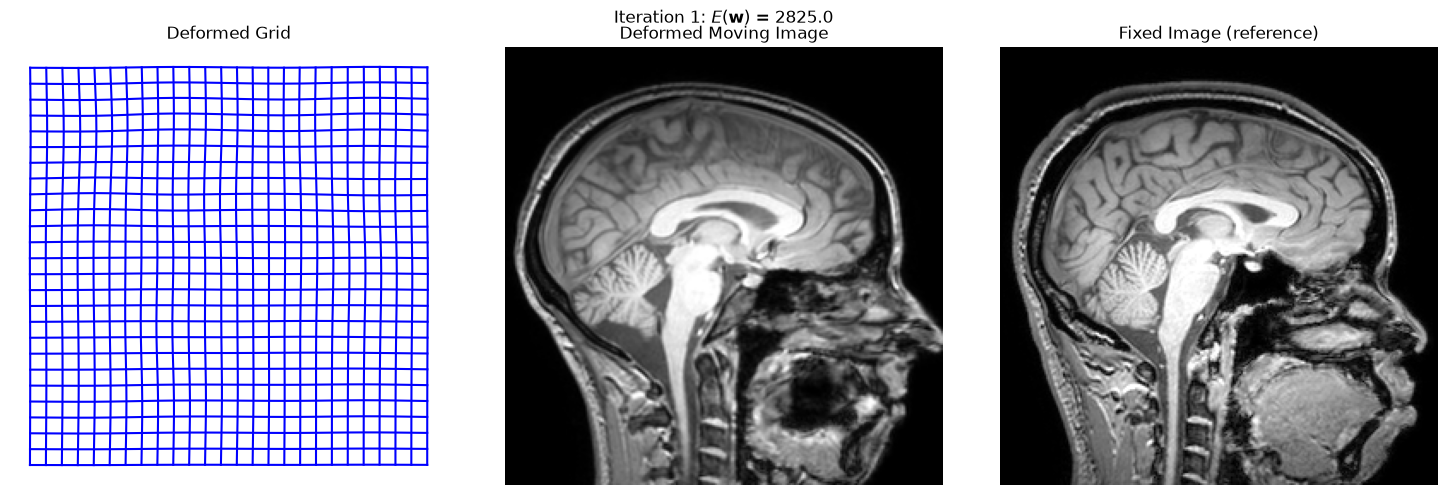

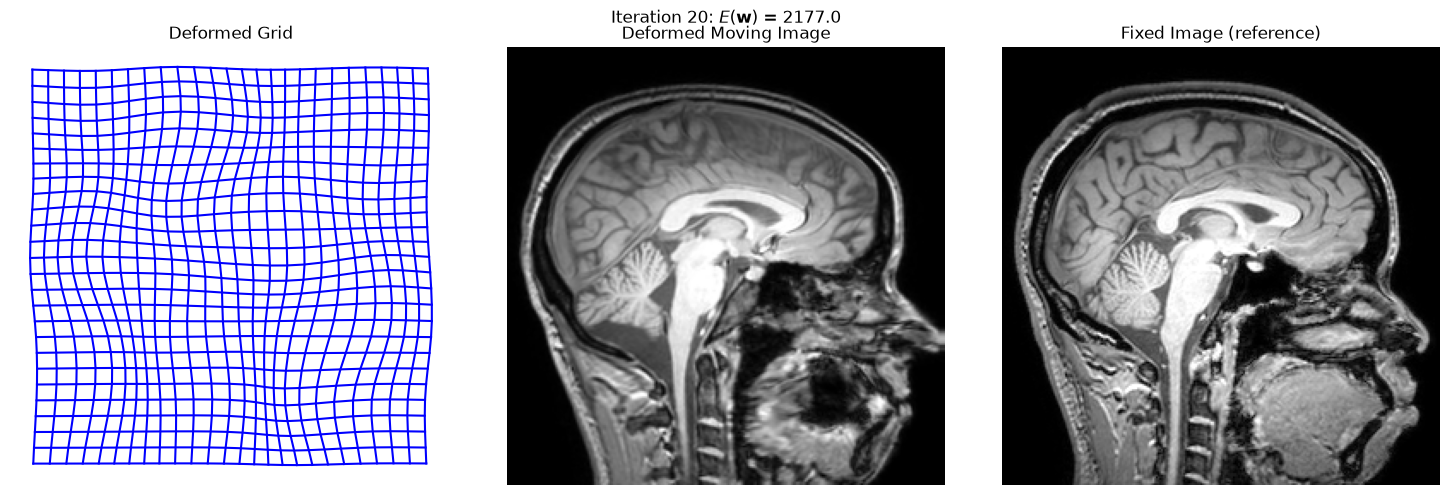

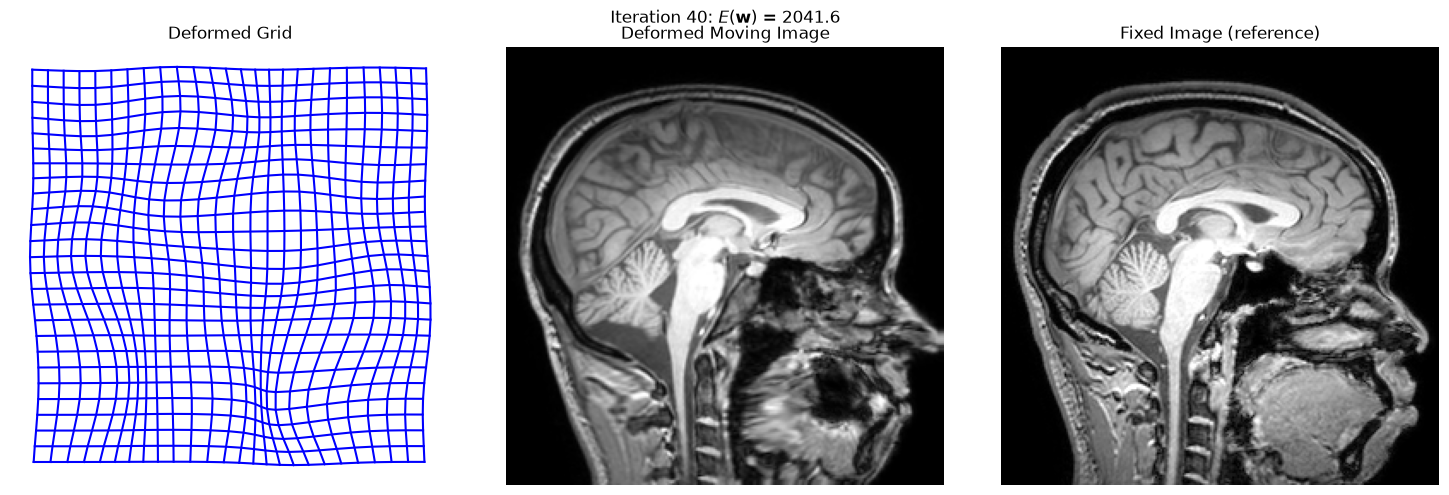

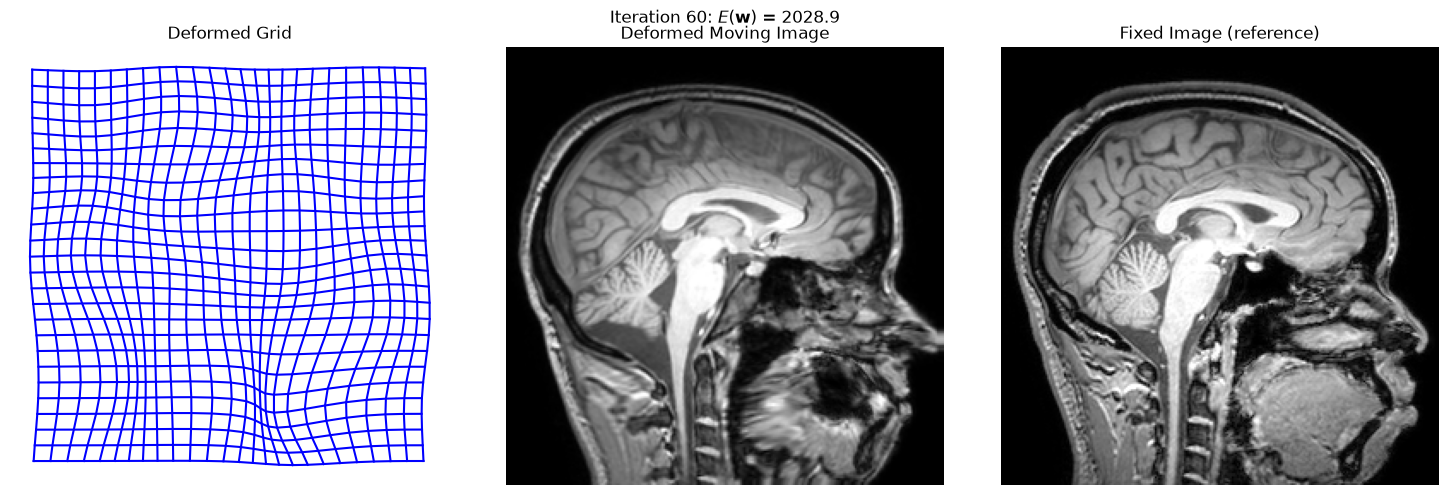

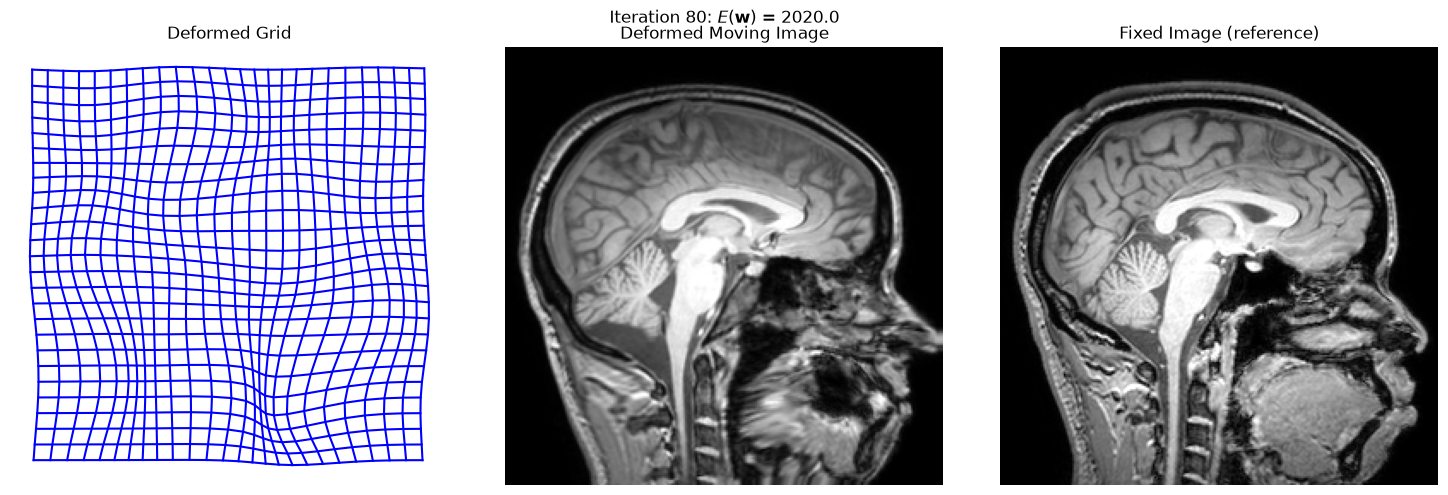

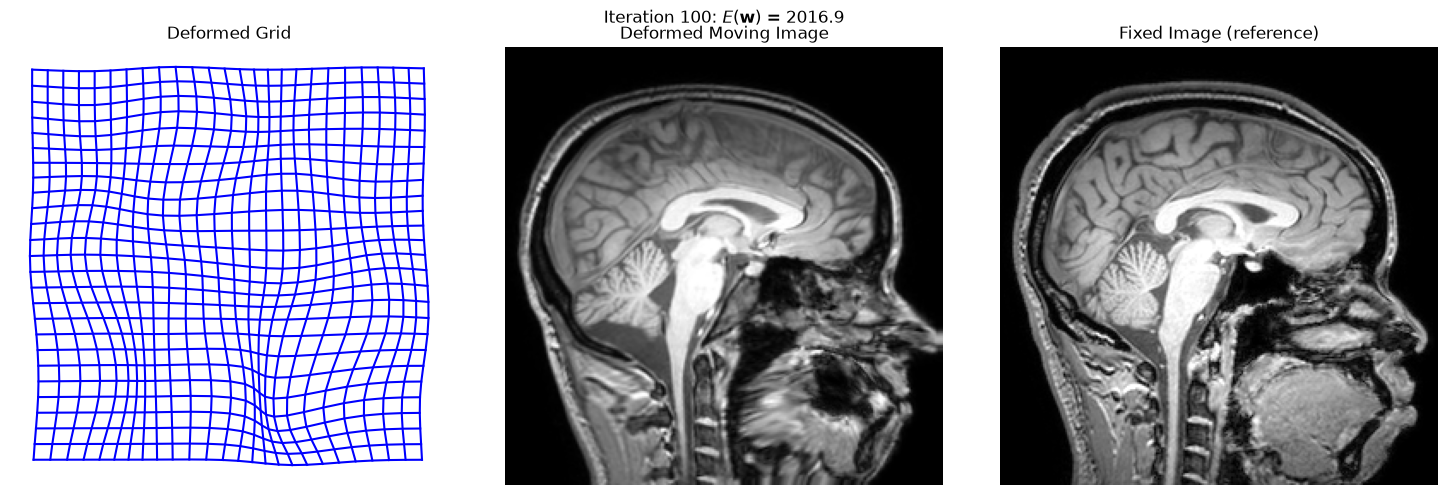

In [31]:
w1_opt, w2_opt, energies, snapshots = register(fixed, moving, Phi, X1, X2,
                                               n_iter=100, delta=0.001, use_lm=False)

for it, (w1_it, w2_it) in snapshots.items():
    Y1, Y2, warped_img = warp_and_resample(w1_it, w2_it, moving, Phi, X1, X2)
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # (1) Deformed image grid
    visualize_grid(axes[0], Y1, Y2)
    axes[0].set_title("Deformed Grid")
    
    # (2) Deformed moving image
    visualize_image(axes[1], warped_img, cmap='gray', vmin=0, vmax=1)
    axes[1].set_title("Deformed Moving Image")
    
    # (3) Fixed image as reference
    visualize_image(axes[2], fixed, cmap='gray', vmin=0, vmax=1)
    axes[2].set_title("Fixed Image (reference)")
    
    plt.suptitle(f"Iteration {it}: $E(\\mathbf{{w}})$ = {energies[it]:.1f}", fontsize=12)
    plt.tight_layout()
    plt.show()

### Task 4.4 Energy across iterations

The energy $E(\mathbf{w})$ is plotted for all 100 iterations. Iteration 0 corresponds to the initial state without deformation.

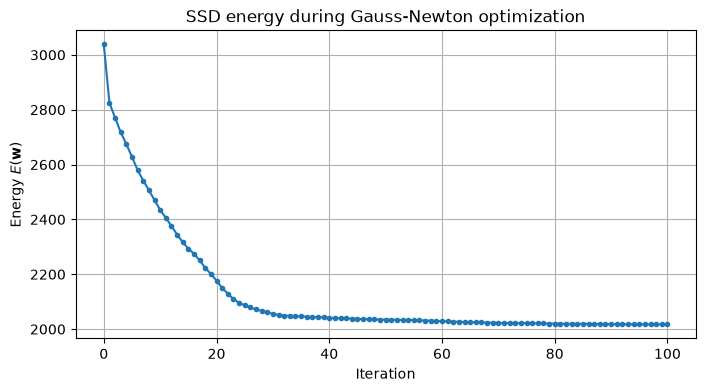

Initial energy: 3037.8
Final energy:   2016.9
Reduction:      33.6 %
Iterations where the energy increased: 0


In [32]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(len(energies)), energies, 'o-', markersize=3)
ax.set_xlabel("Iteration")
ax.set_ylabel("Energy $E(\\mathbf{w})$")
ax.set_title("SSD energy during Gauss-Newton optimization")
ax.grid()
plt.show()

print(f"Initial energy: {energies[0]:.1f}")
print(f"Final energy:   {energies[-1]:.1f}")
print(f"Reduction:      {100 * (1 - energies[-1] / energies[0]):.1f} %")
print(f"Iterations where the energy increased: {np.sum(np.diff(energies) > 0)}")

### Task 4.5 Alignment before and after registration

To assess the result, the absolute intensity differences $|\mathcal{F}(\mathbf{x}) - \mathcal{M}(\mathbf{y}(\mathbf{x}, \mathbf{w}))|$ are shown before registration ($\mathbf{w} = \mathbf{0}$) and after 100 iterations. Dark regions indicate good agreement between the two images.

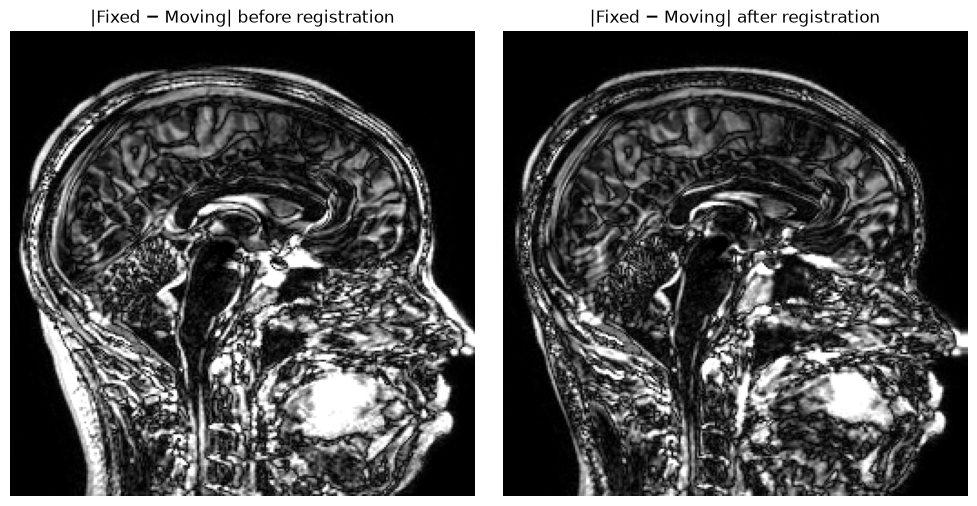

In [33]:
_, _, warped_final = warp_and_resample(w1_opt, w2_opt, moving, Phi, X1, X2)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

visualize_image(axes[0], np.abs(fixed - moving), cmap='gray', vmin=0, vmax=0.5)
axes[0].set_title("|Fixed − Moving| before registration")

visualize_image(axes[1], np.abs(fixed - warped_final), cmap='gray', vmin=0, vmax=0.5)
axes[1].set_title("|Fixed − Moving| after registration")

plt.tight_layout()
plt.show()

## Task 5: Experiment with different numbers of Basis Functions

Re-run the registration when the number of basis functions is altered (e.g., $3x3$ or $7x7$ instead of $5x5$) and inspect the outcomes. In your report, comment on differences in the results.

# 4. Conclusion